# Assignment 8

In [2]:
import re
import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud, STOPWORDS
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical


# Q1. Text Preprocessing with NLTK

**Question:** Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).

1. Convert text to lowercase and remove punctuation using `re`.
2. Tokenize the text into words and sentences.
3. Split using `split()` and `word_tokenize()` and compare how Python `split` and NLTK's `word_tokenize()` differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).

Cleaned text:
 technology has quietly become the backbone of modern life shaping how we work learn and connect with one another artificial intelligence in particular is transforming industries by automating repetitive tasks and uncovering patterns that humans often miss programmers write code that turns abstract ideas into tools used by millions of people every day its amazing how a few lines of wellwritten code can solve problems that once took teams of people weeks to finish however technology also raises important questions about privacy fairness and the future of human jobs learning to build and question technology at the same time is in my opinion the most valuable skill a student can develop today 

Number of sentences: 6
1. Technology has quietly become the backbone of modern life, shaping how we work, learn, and connect with one another.
2. Artificial intelligence, in particular, is transforming industries by automating repetitive tasks and uncovering patterns that humans often

[nltk_data] Downloading package punkt to /Users/kanangarg/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


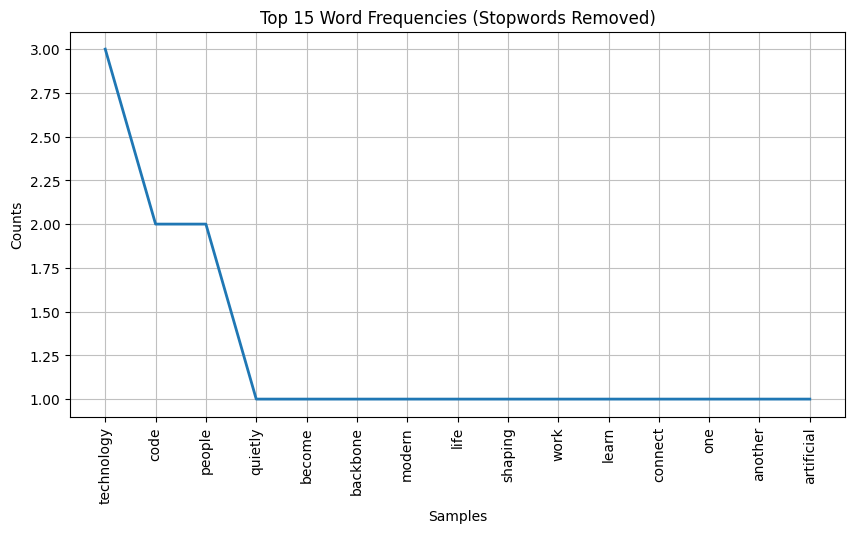

In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Technology has quietly become the backbone of modern life, shaping how we work, learn, and connect with one another. Artificial intelligence, in particular, is transforming industries by automating repetitive tasks and uncovering patterns that humans often miss. Programmers write code that turns abstract ideas into tools used by millions of people every day. It's amazing how a few lines of well-written code can solve problems that once took teams of people weeks to finish. However, technology also raises important questions about privacy, fairness, and the future of human jobs. Learning to build and question technology at the same time is, in my opinion, the most valuable skill a student can develop today."""

# 1. Lowercase + remove punctuation using re
lower_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)
print("Cleaned text:\n", clean_text, "\n")

# 2. Tokenization
sentences = sent_tokenize(text)          # use original text so sentence boundaries survive
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s}")

words = word_tokenize(clean_text)
print("\nWord tokens:", words)

# 3. split() vs word_tokenize() (on text WITH punctuation to show the difference)
split_tokens = lower_text.split()
nltk_tokens = word_tokenize(lower_text)

print("\nsplit() count        :", len(split_tokens))
print("word_tokenize() count:", len(nltk_tokens))
print("\nsplit() sample       :", split_tokens[:12])
print("word_tokenize sample :", nltk_tokens[:12])

# Tokens present in one result but not the other
print("\nOnly in split()        :", sorted(set(split_tokens) - set(nltk_tokens)))
print("Only in word_tokenize():", sorted(set(nltk_tokens) - set(split_tokens)))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nBefore stopword removal:", len(words))
print("After stopword removal :", len(filtered_words))
print("Filtered words:", filtered_words)

# 5. Word frequency distribution (excluding stopwords)
freq = FreqDist(filtered_words)
print("\nTop 10 words:", freq.most_common(10))

plt.figure(figsize=(10, 5))
freq.plot(15, title="Top 15 Word Frequencies (Stopwords Removed)")
plt.show()

# Q2. Stemming and Lemmatization

**Question:** Using the same paragraph from Q1:

1. Extract all words with only alphabets using `re.findall()`.
2. Remove stop words using NLTK's stopword list.
3. Perform stemming with `PorterStemmer`.
4. Perform lemmatization with `WordNetLemmatizer`.
5. Compare the stemmed and lemmatized outputs and explain when you'd prefer one over the other.

In [4]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

text = """Technology has quietly become the backbone of modern life, shaping how we work, learn, and connect with one another. Artificial intelligence, in particular, is transforming industries by automating repetitive tasks and uncovering patterns that humans often miss. Programmers write code that turns abstract ideas into tools used by millions of people every day. It's amazing how a few lines of well-written code can solve problems that once took teams of people weeks to finish. However, technology also raises important questions about privacy, fairness, and the future of human jobs. Learning to build and question technology at the same time is, in my opinion, the most valuable skill a student can develop today."""

# 1. Extract alphabet-only words
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print("Total words:", len(words))
print(words, "\n")

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered = [w for w in words if w not in stop_words]
print("After stopword removal:", len(filtered))
print(filtered, "\n")

# 3. Stemming
stemmer = PorterStemmer()
stemmed = [stemmer.stem(w) for w in filtered]
print("Stemmed:", stemmed, "\n")

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]
print("Lemmatized:", lemmatized, "\n")

# 5. Comparison table
df = pd.DataFrame({
    'Original': filtered,
    'Stemmed': stemmed,
    'Lemmatized': lemmatized
})
print(df.to_string(index=False))

# Words where the outputs differ
diff = df[df['Stemmed'] != df['Lemmatized']].drop_duplicates()
print("\nWords where stemming and lemmatization differ:")
print(diff.to_string(index=False))

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


Total words: 114
['technology', 'has', 'quietly', 'become', 'the', 'backbone', 'of', 'modern', 'life', 'shaping', 'how', 'we', 'work', 'learn', 'and', 'connect', 'with', 'one', 'another', 'artificial', 'intelligence', 'in', 'particular', 'is', 'transforming', 'industries', 'by', 'automating', 'repetitive', 'tasks', 'and', 'uncovering', 'patterns', 'that', 'humans', 'often', 'miss', 'programmers', 'write', 'code', 'that', 'turns', 'abstract', 'ideas', 'into', 'tools', 'used', 'by', 'millions', 'of', 'people', 'every', 'day', 'it', 's', 'amazing', 'how', 'a', 'few', 'lines', 'of', 'well', 'written', 'code', 'can', 'solve', 'problems', 'that', 'once', 'took', 'teams', 'of', 'people', 'weeks', 'to', 'finish', 'however', 'technology', 'also', 'raises', 'important', 'questions', 'about', 'privacy', 'fairness', 'and', 'the', 'future', 'of', 'human', 'jobs', 'learning', 'to', 'build', 'and', 'question', 'technology', 'at', 'the', 'same', 'time', 'is', 'in', 'my', 'opinion', 'the', 'most', 'val

# Q3. Bag of Words and TF-IDF

**Question:** Choose 3 short texts of your own (e.g., different news headlines, product reviews).

1. Use `CountVectorizer` to generate the Bag of Words representation.
2. Use `TfidfVectorizer` to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [5]:
# Three short texts: a news headline, a product review, a sports report
texts = [
    "The government announced a new policy to boost electric vehicle production and reduce pollution in major cities.",
    "This phone has an amazing camera and a great battery life, but the charger is slow and the price is high.",
    "India won the cricket match by five wickets after a brilliant century from the opening batter."
]
labels = ["Text 1 (News)", "Text 2 (Review)", "Text 3 (Sports)"]

# 1. Bag of Words using CountVectorizer
cv = CountVectorizer(stop_words='english')
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=labels)
print("Bag of Words matrix:")
print(bow_df, "\n")

# 2. TF-IDF using TfidfVectorizer
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
features = tfidf.get_feature_names_out()
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=features, index=labels)
print("TF-IDF matrix:")
print(tfidf_df.round(3), "\n")

# 3. Top 3 keywords per text
for i, label in enumerate(labels):
    row = tfidf_matrix[i].toarray().flatten()
    top_idx = np.argsort(row)[::-1][:3]
    print(f"{label} - Top 3 keywords:")
    for idx in top_idx:
        print(f"   {features[idx]:<12} {row[idx]:.3f}")
    print()

Bag of Words matrix:
                 amazing  announced  batter  battery  boost  brilliant  \
Text 1 (News)          0          1       0        0      1          0   
Text 2 (Review)        1          0       0        1      0          0   
Text 3 (Sports)        0          0       1        0      0          1   

                 camera  century  charger  cities  ...  phone  policy  \
Text 1 (News)         0        0        0       1  ...      0       1   
Text 2 (Review)       1        0        1       0  ...      1       0   
Text 3 (Sports)       0        1        0       0  ...      0       0   

                 pollution  price  production  reduce  slow  vehicle  wickets  \
Text 1 (News)            1      0           1       1     0        1        0   
Text 2 (Review)          0      1           0       0     1        0        0   
Text 3 (Sports)          0      0           0       0     0        0        1   

                 won  
Text 1 (News)      0  
Text 2 (Review)   

# Q4. Jaccard and Cosine Similarity

**Question:** Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).

1. Preprocess and tokenize both texts.
2. Calculate:
   - a. Jaccard Similarity using sets
   - b. Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`
   - c. Analyze which similarity metric gives better insights in your case.

In [6]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Two texts on different technologies
text1 = """Artificial intelligence allows machines to learn from data and make decisions without explicit programming.
Machine learning models detect patterns in large datasets and improve with experience.
AI is used in healthcare, finance, and self-driving cars to automate complex tasks.
Deep learning, a branch of AI, uses neural networks to understand images, speech, and language.
Companies rely on AI to analyze data and predict future trends."""

text2 = """Blockchain is a decentralized digital ledger that records transactions across many computers.
Each block contains data and is linked to the previous block using cryptography.
Because records cannot be changed easily, blockchain provides security and transparency.
It is widely used in cryptocurrency, supply chains, and digital contracts.
Companies use blockchain to verify transactions without relying on a central authority."""

# 1. Preprocess and tokenize
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    tokens = word_tokenize(text)
    return [w for w in tokens if w not in stop_words]

tokens1 = preprocess(text1)
tokens2 = preprocess(text2)
print("Text 1 tokens:", tokens1, "\n")
print("Text 2 tokens:", tokens2, "\n")

# 2a. Jaccard similarity using sets
set1, set2 = set(tokens1), set(tokens2)
intersection = set1 & set2
union = set1 | set2
jaccard = len(intersection) / len(union)

print("Common words:", intersection)
print("Intersection size:", len(intersection))
print("Union size       :", len(union))
print(f"Jaccard Similarity: {jaccard:.4f}\n")

# 2b. Cosine similarity using TfidfVectorizer
clean1 = " ".join(tokens1)
clean2 = " ".join(tokens2)

tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform([clean1, clean2])
cosine = cosine_similarity(matrix[0], matrix[1])[0][0]
print(f"Cosine Similarity (TF-IDF): {cosine:.4f}")

Text 1 tokens: ['artificial', 'intelligence', 'allows', 'machines', 'learn', 'data', 'make', 'decisions', 'without', 'explicit', 'programming', 'machine', 'learning', 'models', 'detect', 'patterns', 'large', 'datasets', 'improve', 'experience', 'ai', 'used', 'healthcare', 'finance', 'selfdriving', 'cars', 'automate', 'complex', 'tasks', 'deep', 'learning', 'branch', 'ai', 'uses', 'neural', 'networks', 'understand', 'images', 'speech', 'language', 'companies', 'rely', 'ai', 'analyze', 'data', 'predict', 'future', 'trends'] 

Text 2 tokens: ['blockchain', 'decentralized', 'digital', 'ledger', 'records', 'transactions', 'across', 'many', 'computers', 'block', 'contains', 'data', 'linked', 'previous', 'block', 'using', 'cryptography', 'records', 'changed', 'easily', 'blockchain', 'provides', 'security', 'transparency', 'widely', 'used', 'cryptocurrency', 'supply', 'chains', 'digital', 'contracts', 'companies', 'use', 'blockchain', 'verify', 'transactions', 'without', 'relying', 'central', 

[nltk_data] Downloading package punkt to /Users/kanangarg/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kanangarg/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Q5. Sentiment Analysis and Word Cloud

**Question:** Write a short review for a product or service.

1. Use TextBlob or VADER to find polarity & subjectivity for each review.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using the `wordcloud` library for all positive reviews.

                                                                                                                  Review  Polarity  Subjectivity Sentiment
This smartphone is absolutely amazing. The camera is brilliant, the battery lasts all day, and the display is beautiful.     0.783         0.967  Positive
                     Excellent delivery service. The package arrived early and the staff were friendly and very helpful.     0.419         0.525  Positive
     The laptop is great for coding. Fast performance, lovely keyboard, and a fantastic screen. Totally worth the price.     0.440         0.620  Positive
           Terrible experience. The headphones stopped working after two days and customer support was rude and useless.    -0.600         0.600  Negative
                         The app keeps crashing and the interface is confusing. Very disappointed with this poor update.    -0.558         0.658  Negative
                           The product arrived on Tuesday in a brown b

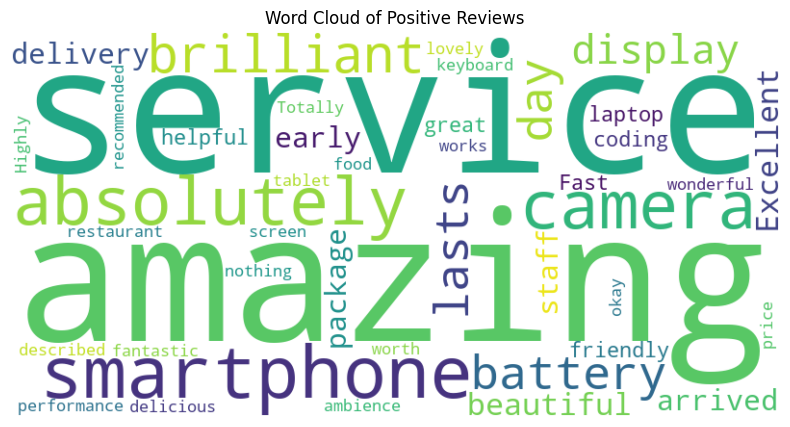

In [7]:
# Short reviews for a product / service (mix of positive, negative, neutral)
reviews = [
    "This smartphone is absolutely amazing. The camera is brilliant, the battery lasts all day, and the display is beautiful.",
    "Excellent delivery service. The package arrived early and the staff were friendly and very helpful.",
    "The laptop is great for coding. Fast performance, lovely keyboard, and a fantastic screen. Totally worth the price.",
    "Terrible experience. The headphones stopped working after two days and customer support was rude and useless.",
    "The app keeps crashing and the interface is confusing. Very disappointed with this poor update.",
    "The product arrived on Tuesday in a brown box. It has a black color and comes with a charger.",
    "The restaurant has a wonderful ambience, delicious food, and amazing service. Highly recommended!",
    "The tablet is okay. It works as described and nothing more."
]

# 1. Polarity and subjectivity using TextBlob
data = []
for r in reviews:
    blob = TextBlob(r)
    data.append({
        'Review': r,
        'Polarity': round(blob.sentiment.polarity, 3),
        'Subjectivity': round(blob.sentiment.subjectivity, 3)
    })

df = pd.DataFrame(data)

# 2. Classify: Positive / Negative / Neutral
def classify(p):
    if p > 0.1:
        return 'Positive'
    elif p < -0.1:
        return 'Negative'
    return 'Neutral'

df['Sentiment'] = df['Polarity'].apply(classify)

pd.set_option('display.max_colwidth', 70)
print(df[['Review', 'Polarity', 'Subjectivity', 'Sentiment']].to_string(index=False))
print("\nSentiment counts:")
print(df['Sentiment'].value_counts())

# 3. Word cloud for positive reviews
positive_text = " ".join(df[df['Sentiment'] == 'Positive']['Review'])

stopwords = set(STOPWORDS)
wc = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords=stopwords,
    colormap='viridis'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()

# Q6. Text Generation with Keras

**Question:** Choose your own paragraph (~100 words) as training data.

1. Tokenize text using `Tokenizer()` from `keras.preprocessing.text`.
2. Create input sequences and build a simple LSTM or Dense model.
3. Train the model and generate 2-3 new lines of text starting from any seed word you provide.

In [8]:
# Step 1: Training paragraph (approximately 100 words)

text = """Technology plays an important role in our daily lives.
It helps students learn new things and improve their knowledge.
Artificial intelligence makes computers smarter and helps people solve problems.
Students use technology for education, communication and research.
Online learning provides access to information from anywhere.
Modern applications make everyday tasks easier and faster.
Technology also helps businesses improve their services.
However, people should use technology wisely and responsibly.
Learning new technologies helps students develop useful skills.
The future of technology will bring many exciting opportunities.
It will continue to change the way people learn and work."""

print("Training Text:")
print(text)


# Step 2: Tokenize the text

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("\nTotal unique words:", total_words - 1)


# Step 3: Create input sequences

input_sequences = []

for sentence in text.lower().split('.'):
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)


# Step 4: Pad sequences

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = to_categorical(y, num_classes=total_words)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)


# Step 5: Build the LSTM model

model = Sequential()

model.add(Embedding(total_words, 64))
model.add(LSTM(100))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


# Step 6: Train the model

model.fit(X, y, epochs=100, verbose=1)


# Step 7: Generate new text

seed_text = "technology helps students"

next_words = 30

for _ in range(next_words):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding='pre'
    )

    predicted = model.predict(token_list, verbose=0)
    predicted_word_index = np.argmax(predicted, axis=1)[0]

    output_word = ""

    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            output_word = word
            break

    if output_word == "":
        break

    seed_text += " " + output_word

print("\nGENERATED TEXT:")
words = seed_text.split()

for i in range(0, len(words), 10):
    print(" ".join(words[i:i+10]))

Training Text:
Technology plays an important role in our daily lives.
It helps students learn new things and improve their knowledge.
Artificial intelligence makes computers smarter and helps people solve problems.
Students use technology for education, communication and research.
Online learning provides access to information from anywhere.
Modern applications make everyday tasks easier and faster.
Technology also helps businesses improve their services.
However, people should use technology wisely and responsibly.
Learning new technologies helps students develop useful skills.
The future of technology will bring many exciting opportunities.
It will continue to change the way people learn and work.

Total unique words: 70

Input shape: (85, 10)
Output shape: (85, 71)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.0471 - loss: 4.2627   
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1059 - loss: 4.2519 
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1294 - loss: 4.2430 
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1176 - loss: 4.2313 
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1176 - loss: 4.2157 
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1294 - loss: 4.1932 
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1412 - loss: 4.1580 
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1294 - loss: 4.1103 
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1059 - loss: 4.0555 
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0941 - loss: 4.0385 
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1059 - loss: 4.0188 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1059 - l